# Jets: log p, 2×2 design: higher orders on/off × scalar on/off (5 seeds each)

| arm | label | higher orders (Scat3 Re+Im, Scat4 Mod2 Re+Im) | Scalar_morlet_gaussianK | lam (xseed, t >= 0.99) |
|---|---|---|---|---|
| full | `jets_full` | yes | yes | 1e-2 |
| noscalar | `jets_noscalar` | yes | no | 1e-2 |
| scat2_scalar | `jets_scat2_scalar` | no | yes | 1e-3 |
| scat2 | `jets_scat2` | no | no | 1e-4 |

All arms: L_6 + Scattering 1st + 2nd order, 5 seeds (500-504), same SDE set-up (`jets/launch_jet_SDE.sh`).
**Test:** statistics that only orders 3-4 can carry (time asymmetry: skewness, leverage; cross-scale C_pq; Scat4)
should be lost in `scat2*`. If they are, the higher-order potentials are what produces them.

Data from `python jets/logp_jets.py` (Jean Zay) -> `figures/logp_jets_scat2/logp_jets.npz` (4 arms); this notebook only reads it
(seconds; runs locally too after pulling that one file). Run from `jets/`.

- Theta = Theta_reg(t = 1) at the cross-seed lambda of each arm (table above, window t >= 0.99), unconstrained.
- log p(x) = sum over families of C_F(x) = Theta_F . phi_F(x), **up to the unknown constant -log Z** of each seed:
  only differences under the same Theta are exact (spreads across signals, held-out - training).
- Decomposition by family: share of the variance of log p across signals, Cov(C_F, log p) / Var(log p). Sums to 1;
  a share > 1 or < 0 means families that partly cancel each other.
- **noscalar caveat:** L_6 filter 1 > 0 in 5/5 seeds at lambda 1e-2 (density not normalizable along that direction).

In [ ]:
%matplotlib inline
%load_ext autoreload
%autoreload 2
import numpy as np
import pandas as pd
from IPython.display import display
import logp_jets as lj
pd.set_option('display.float_format', '{:,.3g}'.format, 'display.width', 220)

runs = lj.load(lj.HERE / 'figures' / 'logp_jets_scat2' / 'logp_jets.npz')   # 4-arm run
for a, r in runs.items():
    print(f"{a}: seeds {r['seeds']}, lam {r['lam']:g}, families {r['families'][:-1]}, "
          f"signals train {r['C']['train'].shape[2]}, held-out {r['C']['heldout'].shape[2]}")

## 1. Distribution of log p (training data)
Each seed centred on its own median (removes its -log Z). Left panels: the 5 seeds of an arm; right: all arms
pooled over seeds.

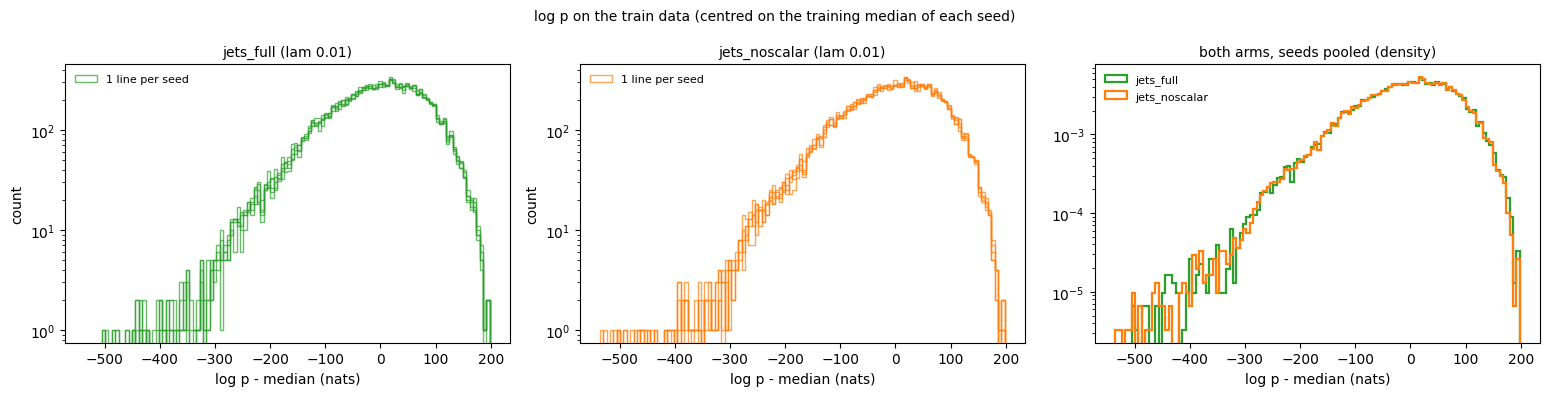

backend: Agg


In [2]:
lj.show(lj.plot_distribution(runs))
import matplotlib; print('backend:', matplotlib.get_backend())

In [3]:
# shape numbers per arm, mean (sd) over seeds
from scipy import stats
rows = []
for a, r in runs.items():
    v = [r['C']['train'][i, -1] for i in range(len(r['seeds']))]
    for name, fn in (('std', np.std), ('skew', stats.skew), ('excess kurtosis', stats.kurtosis),
                     ('median - q0.001', lambda x: np.median(x) - np.quantile(x, 1e-3)),
                     ('q0.999 - median', lambda x: np.quantile(x, 0.999) - np.median(x))):
        vals = [fn(x) for x in v]
        rows.append(dict(arm=a, stat=name, mean=np.mean(vals), sd_over_seeds=np.std(vals, ddof=1)))
display(pd.DataFrame(rows).pivot(index='stat', columns='arm'))

mean               sd_over_seeds              
arm             jets_full jets_noscalar     jets_full jets_noscalar
stat                                                               
excess kurtosis      2.26          1.44         0.218        0.0925
median - q0.001       386           388          7.63          2.06
q0.999 - median       178           174         0.345          1.13
skew               -0.786        -0.751        0.0162        0.0109
std                  87.2          86.8         0.258         0.278

## 2. log p per potential family, 4 arms (families missing in an arm are left empty)
C_F(x) = Theta_F . phi_F(x), the contribution of family F to log p of signal x. Error bars = sd over the 5 seeds.
1. **mean C_F** (shaded): level only, its zero depends on where phi_F is centred (a constant in phi_F changes it, not p).
2. **std of C_F across signals** (nats): how much F makes one signal more or less likely than another. TOTAL = std of log p.
   Invariant to constants in phi_F and to -log Z: the main panel.
3. **std of C_F / std of log p** (hatched), same arm: puts arms on one scale. > 1 = F alone would spread log p more
   than it is actually spread, i.e. cancelled by other families. Does not sum to 1 (stds don't add).

In [ ]:
fig, T = lj.plot_family_bars(runs); lj.show(fig)
# same, families summed into groups per signal (edit the prefixes to regroup; every family in exactly one group)
GROUPS = {'L_6': ('L_6',), 'scalar+Scat1+Scat2': ('S_', 'Scat1', 'Scat2'), 'Scat3+Scat4': ('Scat3', 'Scat4')}
fig, Tg = lj.plot_family_bars(runs, groups=GROUPS); lj.show(fig)
display(Tg.pivot(index='family', columns='arm', values=['std_signals', 'std_signals_sd', 'std_norm'])
          .reindex(list(dict.fromkeys(Tg.family))))

In [5]:
# seed robustness (point a): rel_sd = sd over seeds / |mean|
T['rel_sd_share'] = T['var_share_sd'] / T['var_share'].abs()
display(T.pivot(index='family', columns='arm', values=['var_share', 'var_share_sd', 'rel_sd_share', 'corr',
                                                       'std_signals'])
         .reindex(list(dict.fromkeys(T.family))))

var_share               var_share_sd               rel_sd_share                    corr               std_signals              
arm           jets_full jets_noscalar    jets_full jets_noscalar    jets_full jets_noscalar jets_full jets_noscalar   jets_full jets_noscalar
family                                                                                                                                       
L_6              0.0457        0.0213     0.000753       0.00234       0.0165          0.11     0.357         0.365        11.2          5.07
S_morlet         -0.672           NaN       0.0111           NaN       0.0165           NaN    -0.962           NaN        60.9           NaN
Scat1              2.54          1.54       0.0177       0.00379      0.00696       0.00246     0.985          0.99         225           135
Scat2            -0.919        -0.606        0.019         0.005       0.0207       0.00825    -0.925        -0.931        86.6          56.5
Scat3_Real     -0.00105      -0.00112     9.08e-05      9.02e-05       0.0862        0.0803   -0.0721       -0.0805        1.28          1.22
Scat3_Imag      -0.0085       -0.0115      0.00283        0.0019        0.332         0.166    -0.138        -0.204        5.81             5
Scat4_Real_Q1    0.0182        0.0614      0.00377        0.0055        0.207        0.0897     0.355          0.48        4.47          11.1
Scat4_Imag_Q1 -0.000591     -0.000957      3.3e-05      0.000117       0.0559         0.122     -0.16        -0.151       0.322          0.55
TOTAL                 1             1            0             0            0             0         1             1        87.2          86.8

In [6]:
# families that cancel: correlation of C_F between families across signals (seed 0 of each arm)
for a, r in runs.items():
    C = r['C']['train'][0, :-1]
    display(pd.DataFrame(np.corrcoef(C), index=r['families'][:-1], columns=r['families'][:-1])
            .style.background_gradient(cmap='RdBu_r', vmin=-1, vmax=1).format('{:.2f}')
            .set_caption(f'{a}, seed {r["seeds"][0]}: corr(C_F, C_G) across signals'))

,L_6,S_morlet,Scat1,Scat2,Scat3_Real,Scat3_Imag,Scat4_Real_Q1,Scat4_Imag_Q1
L_6,1.00,-0.21,0.28,-0.40,-0.03,-0.18,0.73,-0.71
S_morlet,-0.21,1.00,-0.97,0.87,0.10,0.22,-0.31,0.07
Scat1,0.28,-0.97,1.00,-0.96,-0.10,-0.28,0.44,-0.11
Scat2,-0.40,0.87,-0.96,1.00,0.10,0.31,-0.59,0.16
Scat3_Real,-0.03,0.10,-0.10,0.10,1.00,-0.04,-0.06,0.06
Scat3_Imag,-0.18,0.22,-0.28,0.31,-0.04,1.00,-0.24,0.07
Scat4_Real_Q1,0.73,-0.31,0.44,-0.59,-0.06,-0.24,1.00,-0.43
Scat4_Imag_Q1,-0.71,0.07,-0.11,0.16,0.06,0.07,-0.43,1.00


,L_6,Scat1,Scat2,Scat3_Real,Scat3_Imag,Scat4_Real_Q1,Scat4_Imag_Q1
L_6,1.00,0.31,-0.40,-0.02,-0.22,0.64,-0.68
Scat1,0.31,1.00,-0.96,-0.09,-0.28,0.51,-0.10
Scat2,-0.40,-0.96,1.00,0.10,0.29,-0.66,0.14
Scat3_Real,-0.02,-0.09,0.10,1.00,-0.02,-0.08,0.05
Scat3_Imag,-0.22,-0.28,0.29,-0.02,1.00,-0.19,0.04
Scat4_Real_Q1,0.64,0.51,-0.66,-0.08,-0.19,1.00,-0.46
Scat4_Imag_Q1,-0.68,-0.10,0.14,0.05,0.04,-0.46,1.00


## 3. Held-out data (point c)
Windows of the record never used in training and more than `gap` windows away from every training window, standardized
with the training mean / std. Same Theta on both sets, so the constant cancels: a held-out distribution shifted to the
left (negative TOTAL shift) = held-out signals less likely than training ones, i.e. overfitting (or held-out windows
genuinely different). Scale for "large": the std of log p across signals (section 1).

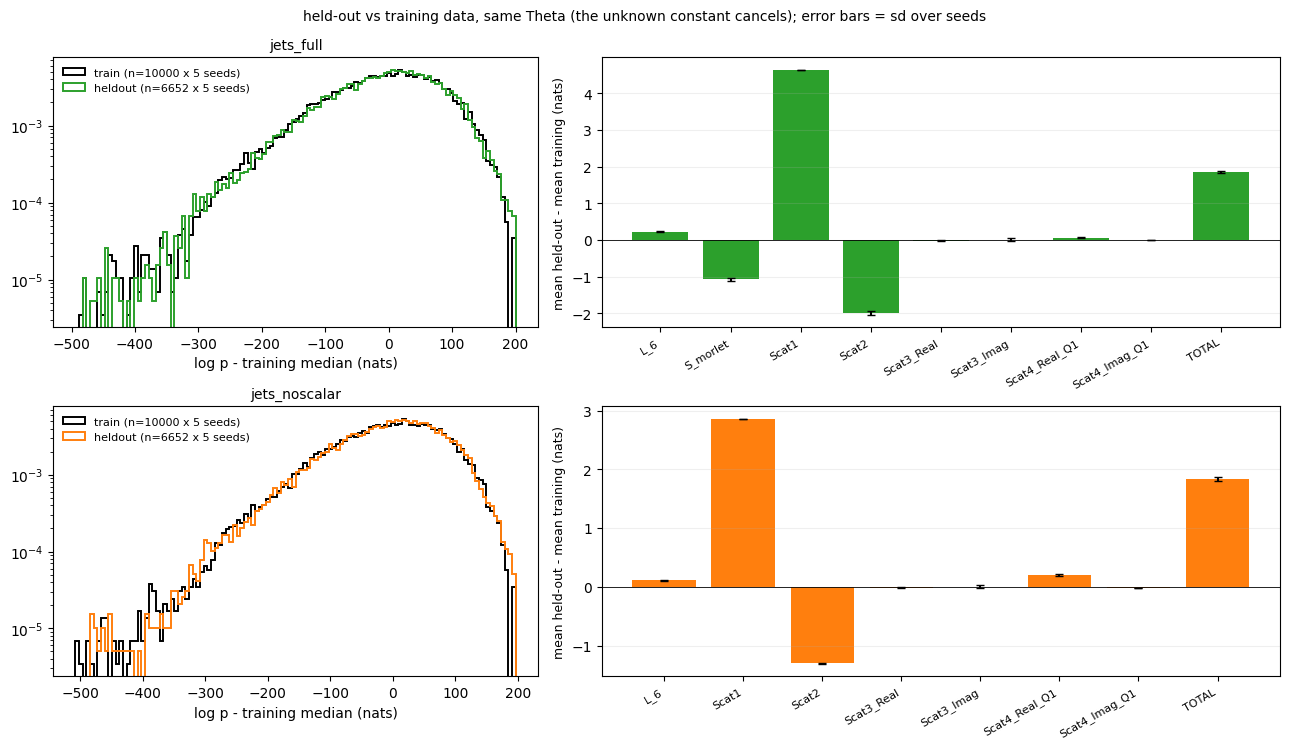

shift                shift_sd               shift_over_std              
arm           jets_full jets_noscalar jets_full jets_noscalar      jets_full jets_noscalar
family                                                                                    
L_6                0.23         0.113   0.00403       0.00743         0.0206        0.0223
S_morlet          -1.07           NaN    0.0461           NaN        -0.0176           NaN
Scat1              4.64          2.86   0.00536       0.00605         0.0207        0.0212
Scat2             -1.99          -1.3    0.0522        0.0127         -0.023       -0.0231
Scat3_Real      -0.0142       -0.0168    0.0111       0.00631        -0.0113       -0.0136
Scat3_Imag       0.0141      -0.00124    0.0283         0.026        0.00182     -7.65e-05
Scat4_Real_Q1    0.0651           0.2    0.0124        0.0145         0.0146         0.018
Scat4_Imag_Q1   -0.0106       -0.0154   0.00169       0.00209         -0.033       -0.0281
TOTAL              1.86          1.83     0.028        0.0297         0.0213        0.0211

In [7]:
fig, H = lj.plot_heldout(runs); lj.show(fig)
display(H.pivot(index='family', columns='arm', values=['shift', 'shift_sd', 'shift_over_std'])
         .reindex(list(dict.fromkeys(H.family))))

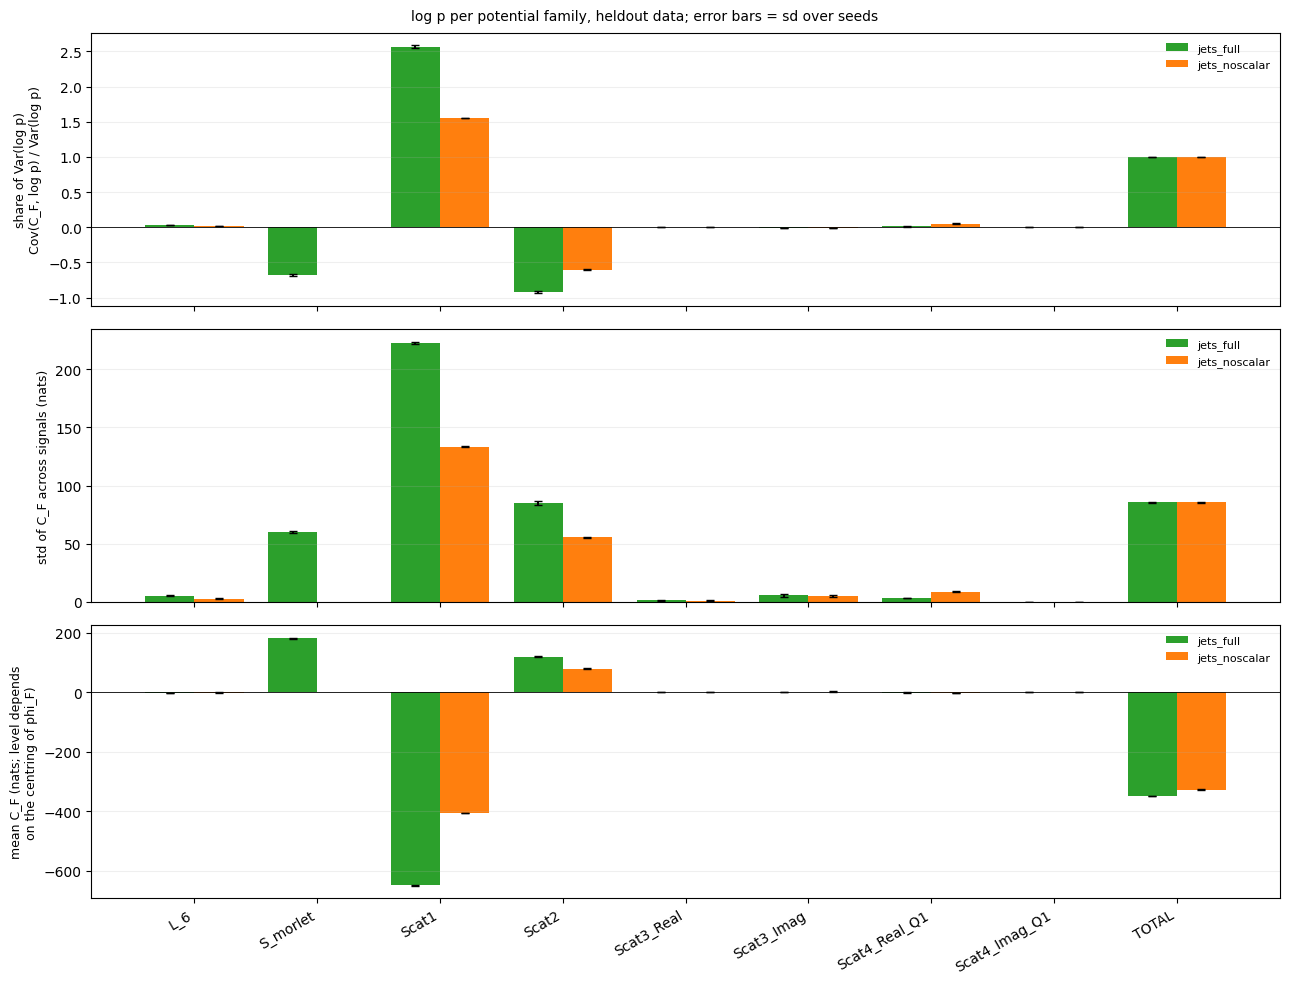

In [8]:
# the family decomposition on the held-out data: does it hold on unseen signals?
fig, Th = lj.plot_family_bars(runs, data_set='heldout'); lj.show(fig)

jets_full:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('S_morlet'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: [np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')]
jets_noscalar:
  scalar+Scat1+Scat2: [np.str_('L_6'), np.str_('Scat1'), np.str_('Scat2')]
  Scat3+Scat4: [np.str_('Scat3_Real'), np.str_('Scat3_Imag'), np.str_('Scat4_Real_Q1'), np.str_('Scat4_Imag_Q1')]


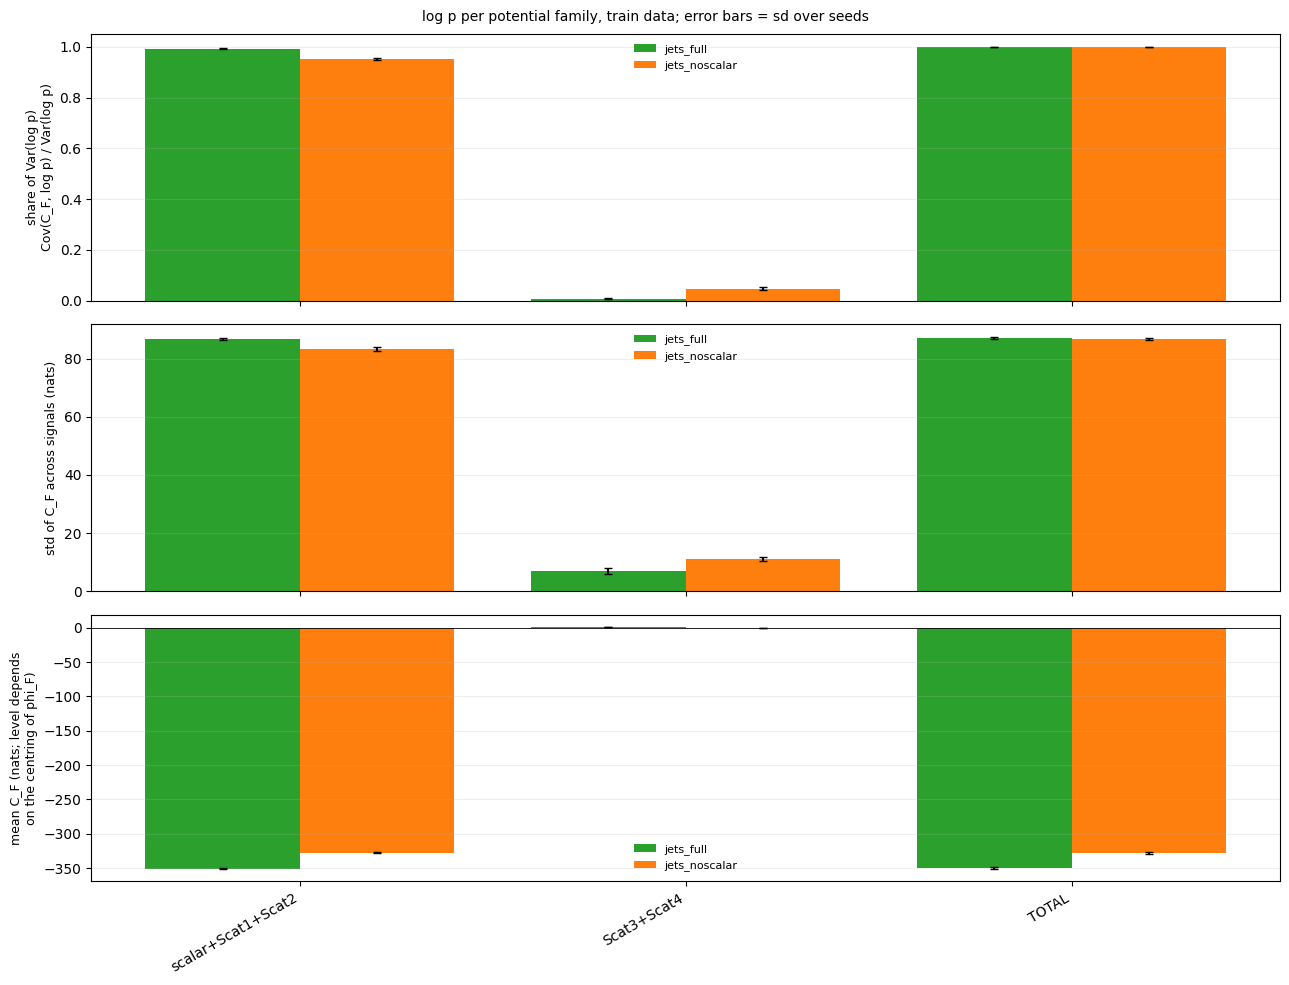

,arm,family,var_share,var_share_sd,corr,std_signals,std_signals_sd
0,jets_full,scalar+Scat1+Scat2,0.992,0.001,0.997,86.8,0.399
1,jets_full,Scat3+Scat4,0.008,0.001,0.105,6.87,1.07
2,jets_full,TOTAL,1,0,1,87.2,0.258
3,jets_noscalar,scalar+Scat1+Scat2,0.952,0.005,0.992,83.3,0.55
4,jets_noscalar,Scat3+Scat4,0.048,0.005,0.375,11.1,0.606
5,jets_noscalar,TOTAL,1,0,1,86.8,0.278


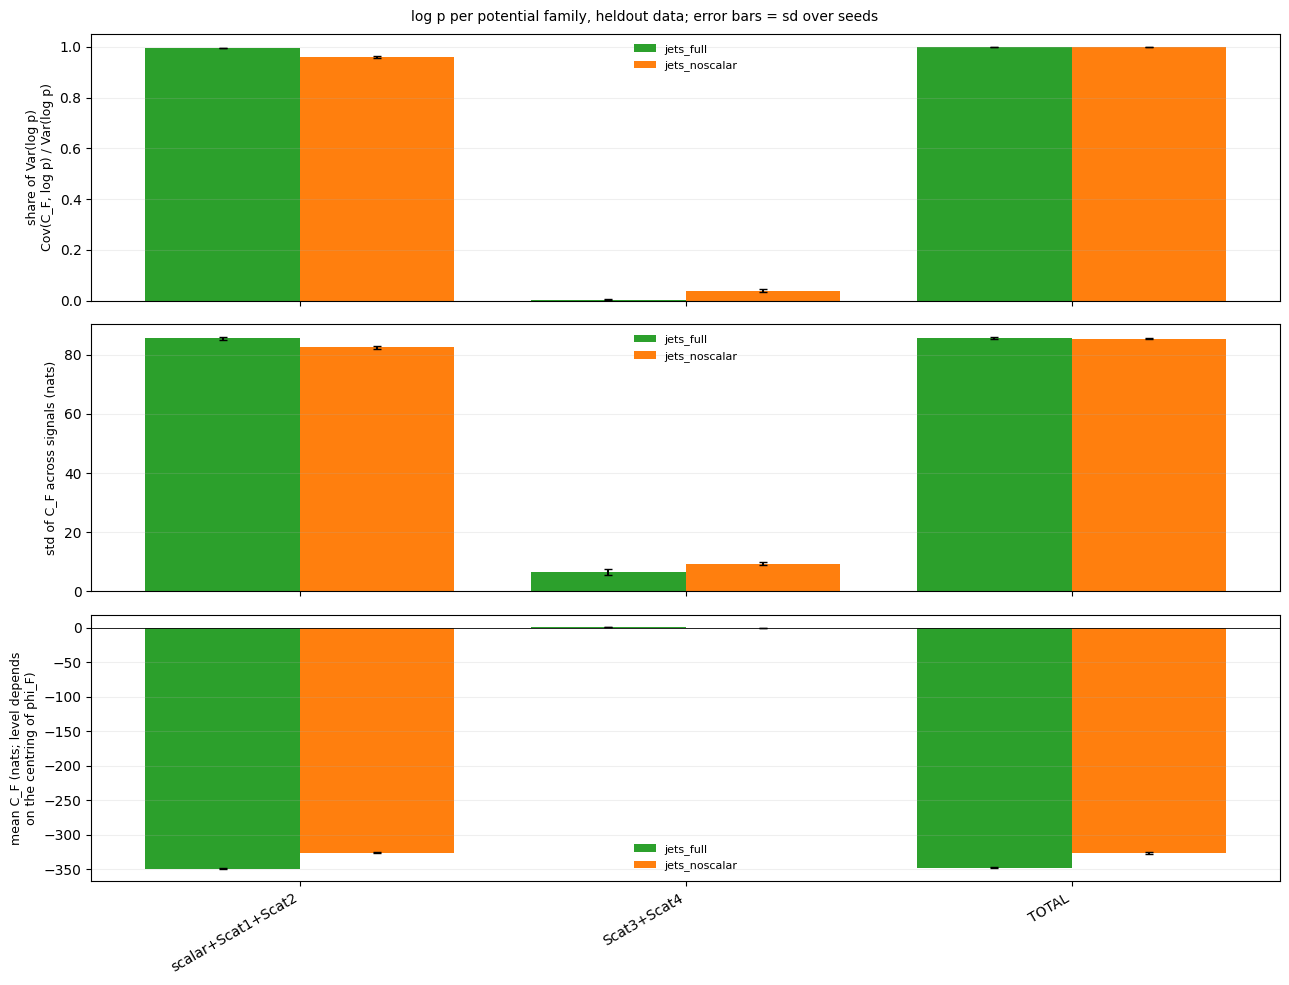

,arm,family,var_share,var_share_sd,corr,std_signals,std_signals_sd
0,jets_full,scalar+Scat1+Scat2,0.995,0.001,0.997,85.6,0.414
1,jets_full,Scat3+Scat4,0.005,0.001,0.065,6.49,1.11
2,jets_full,TOTAL,1,0,1,85.8,0.295
3,jets_noscalar,scalar+Scat1+Scat2,0.96,0.005,0.995,82.6,0.533
4,jets_noscalar,Scat3+Scat4,0.04,0.005,0.366,9.28,0.591
5,jets_noscalar,TOTAL,1,0,1,85.5,0.278


In [9]:
# log p split into two groups: low order (scalar + Scat1 + Scat2) vs high order (Scat3 + Scat4).
# Sum C_F per seed and per signal BEFORE the statistics, so std / corr / seed error bars are those of the group.
HIGH = ('Scat3', 'Scat4')
LOW_NAME, HIGH_NAME = 'scalar+Scat1+Scat2', 'Scat3+Scat4'

def group_runs(runs):
    out = {}
    for arm, r in runs.items():
        fams = r['families'][:-1]                                   # drop TOTAL
        hi = np.array([f.startswith(HIGH) for f in fams])
        print(f'{arm}:\n  {LOW_NAME}: {[f for f, h in zip(fams, hi) if not h]}\n  {HIGH_NAME}: {[f for f, h in zip(fams, hi) if h]}')
        C = {}
        for name, c in r['C'].items():                              # (S, F+1, n), last = TOTAL
            lo_c, hi_c = c[:, :-1][:, ~hi].sum(1), c[:, :-1][:, hi].sum(1)
            C[name] = np.stack([lo_c, hi_c, c[:, -1]], axis=1)
            assert np.allclose(lo_c + hi_c, c[:, -1])
        out[arm] = dict(r, families=[LOW_NAME, HIGH_NAME, 'TOTAL'], C=C)
    return out

runs_g = group_runs(runs)
for ds in ('train', 'heldout'):
    fig, Tg = lj.plot_family_bars(runs_g, data_set=ds); lj.show(fig)
    display(Tg[['arm', 'family', 'var_share', 'var_share_sd', 'corr', 'std_signals', 'std_signals_sd']].round(3))